# Simulación de Montecarlo del juego Yahtzee — Grupo 31

**Actividad didáctica 2-M1.** Simulación de Yahtzee clásico con 2 jugadores, a partir de la guía base del curso,
aplicando la metodología **USA → MODIFICA → CREA**.

| Fase | Qué se hizo |
|---|---|
| **USA** | Se ejecutó y analizó la guía base: dados con distribución uniforme (p = 1/6), 13 categorías, y Montecarlo que evalúa las 32 máscaras de bloqueo. |
| **MODIFICA** | **Error 1:** en el último lanzamiento el jugador siempre relanzaba los 5 dados (`rolls_remaining - 1`). **Error 2:** cambiar `SIMS_PER_MASK` no tenía efecto. **Error 3:** nodo inexistente en el diagrama de flujo. **Error 4:** el "valor teórico" de la convergencia era el último valor simulado. |
| **CREA** | Bono superior (+35 si ≥ 63) y bono de Yahtzee (+100), reglas oficiales. Estrategia mejorada para elegir categoría. Caché de puntuación para acelerar Montecarlo. Análisis de la **Ley de los Grandes Números** con muchas partidas y valores teóricos exactos. |

En el código, cada cambio está marcado con un comentario `# MODIFICA` o `# CREA`.

## 1. Motor del juego (USA + MODIFICA + CREA)

In [1]:
import random
from collections import Counter
from dataclasses import dataclass, field
from functools import lru_cache
from typing import List, Dict, Optional, Tuple

# ===============================
# Parámetros Montecarlo
# ===============================
SIMS_PER_MASK = 300   # nº de simulaciones por máscara de bloqueo (32 máscaras)
SEED = 42             # semilla para reproducibilidad; None = aleatorio

if SEED is not None:
    random.seed(SEED)

# ===============================
# Utilidades de dados (USA: sin cambios)
# ===============================
def roll_single_die() -> int:
    """Devuelve un entero uniforme en [1,6] (distribución uniforme discreta, p = 1/6)."""
    return random.randint(1, 6)

def roll_dice(values: List[int], locked: List[bool]) -> None:
    """Lanza los dados no bloqueados, actualizando 'values' in place."""
    for i, is_locked in enumerate(locked):
        if not is_locked:
            values[i] = roll_single_die()

def has_sequence(values, needed_len: int) -> bool:
    """¿Existe una secuencia consecutiva de longitud 'needed_len'? (ignora duplicados)."""
    uniq = sorted(set(values))
    if not uniq:
        return False
    longest = curr = 1
    for i in range(1, len(uniq)):
        if uniq[i] == uniq[i-1] + 1:
            curr += 1
            longest = max(longest, curr)
        else:
            curr = 1
    return longest >= needed_len

# ===============================
# Puntuación
# ===============================
CATEGORIES_ORDER = [
    "ones","twos","threes","fours","fives","sixes",
    "threeOfKind","fourOfKind","fullHouse","smallStraight",
    "largeStraight","yahtzee","chance"
]
UPPER = ["ones","twos","threes","fours","fives","sixes"]
UPPER_BONUS_THRESHOLD = 63   # CREA: regla oficial del bono superior
UPPER_BONUS = 35
YAHTZEE_BONUS = 100          # CREA: regla oficial del bono por Yahtzee adicional

# CREA (optimización): la puntuación sólo depende de la combinación ordenada de dados
# (252 combinaciones posibles), así que se guarda en caché para acelerar Montecarlo.
@lru_cache(maxsize=None)
def _score_sorted(category: str, dice: Tuple[int, ...]) -> int:
    counts = Counter(dice)
    freqs = list(counts.values())
    total = sum(dice)
    if category in UPPER:
        num = UPPER.index(category) + 1
        return counts.get(num, 0) * num
    if category == "threeOfKind":
        return total if any(f >= 3 for f in freqs) else 0
    if category == "fourOfKind":
        return total if any(f >= 4 for f in freqs) else 0
    if category == "fullHouse":
        return 25 if (2 in freqs and 3 in freqs) else 0
    if category == "smallStraight":
        return 30 if has_sequence(dice, 4) else 0
    if category == "largeStraight":
        return 40 if has_sequence(dice, 5) else 0
    if category == "yahtzee":
        return 50 if 5 in freqs else 0
    if category == "chance":
        return total
    return 0

def score_hand(category: str, dice: List[int]) -> int:
    return _score_sorted(category, tuple(sorted(dice)))

def best_category_score(dice: List[int], available: List[str]) -> Tuple[str, int]:
    """Estrategia original (USA): la categoría con mayor puntaje inmediato."""
    best_cat, best = None, -1
    for cat in available:
        sc = score_hand(cat, dice)
        if sc > best:
            best, best_cat = sc, cat
    return best_cat, best

# CREA: estrategia mejorada de elección de categoría.
# La estrategia original "gasta" categorías valiosas (p. ej. usa 'chance' en el primer turno).
# Aquí se resta a cada puntaje un valor de referencia: lo que esa categoría suele aportar
# en promedio si se guarda para después. Así se elige la categoría con mejor "ganancia neta".
REFERENCE_VALUE = {
    "ones": 2, "twos": 5, "threes": 8, "fours": 11, "fives": 14, "sixes": 17,
    "threeOfKind": 17, "fourOfKind": 8, "fullHouse": 12, "smallStraight": 18,
    "largeStraight": 14, "yahtzee": 10, "chance": 22,
}

def smart_category_score(dice: List[int], available: List[str]) -> Tuple[str, int]:
    best_cat, best_adj, best_sc = None, None, 0
    for cat in available:
        sc = score_hand(cat, dice)
        adj = sc - REFERENCE_VALUE[cat]
        if best_adj is None or adj > best_adj:
            best_cat, best_adj, best_sc = cat, adj, sc
    return best_cat, best_sc

# ===============================
# Estructuras de juego
# ===============================
@dataclass
class PlayerState:
    name: str
    scores: Dict[str, Optional[int]] = field(default_factory=lambda: {c: None for c in CATEGORIES_ORDER})
    yahtzee_bonus: int = 0   # CREA
    total: int = 0

    def available_categories(self) -> List[str]:
        return [c for c, v in self.scores.items() if v is None]

    def upper_sum(self) -> int:
        return sum(self.scores[c] or 0 for c in UPPER)

    def upper_bonus(self) -> int:
        """CREA: +35 si la sección superior suma 63 o más."""
        return UPPER_BONUS if self.upper_sum() >= UPPER_BONUS_THRESHOLD else 0

    def set_score(self, category: str, points: int, dice: Optional[List[int]] = None) -> None:
        # CREA: bono de 100 por cada Yahtzee adicional si la casilla Yahtzee ya tiene 50.
        if dice is not None and len(set(dice)) == 1 and self.scores["yahtzee"] == 50:
            self.yahtzee_bonus += YAHTZEE_BONUS
        self.scores[category] = points
        self.total = (sum(v for v in self.scores.values() if v is not None)
                      + self.upper_bonus() + self.yahtzee_bonus)

@dataclass
class GameStats:
    total_rolls: int = 0
    face_hist: Counter = field(default_factory=Counter)
    yahtzees: int = 0   # CREA: nº de turnos que terminaron en Yahtzee
    turns: int = 0

    def update_from_roll(self, values: List[int]) -> None:
        self.total_rolls += len(values)
        self.face_hist.update(values)

@dataclass
class GameState:
    players: List[PlayerState]
    current_player_idx: int = 0
    turn_in_round: int = 0
    dice_values: List[int] = field(default_factory=lambda: [0]*5)
    locked: List[bool] = field(default_factory=lambda: [False]*5)
    rolls_left: int = 3
    stats: GameStats = field(default_factory=GameStats)

    def reset_turn(self):
        self.dice_values = [0]*5
        self.locked = [False]*5
        self.rolls_left = 3

    @property
    def current_player(self) -> PlayerState:
        return self.players[self.current_player_idx]

    def advance_player(self):
        self.current_player_idx = (self.current_player_idx + 1) % len(self.players)
        if self.current_player_idx == 0:
            self.turn_in_round += 1

# ===============================
# Montecarlo para decidir bloqueos
# ===============================
ALL_KEEP_MASKS = [[(m >> i) & 1 == 1 for i in range(5)] for m in range(32)]

def all_keep_masks() -> List[List[bool]]:
    """Las 32 máscaras posibles de bloqueo para 5 dados."""
    return ALL_KEEP_MASKS

def simulate_expected_value_after_keeps(current_values, keep_mask, rolls_remaining,
                                        available_categories, sims, chooser=best_category_score) -> float:
    """
    Estima por Montecarlo el valor esperado (EV) de la mejor categoría si se conservan
    los dados de 'keep_mask' y se relanzan los demás 'rolls_remaining' veces
    (aproximación de 1 paso: la máscara no cambia durante la simulación).
    """
    if rolls_remaining <= 0 or all(keep_mask):
        _, sc = chooser(current_values, available_categories)
        return float(sc)
    unlocked_idx = [i for i, b in enumerate(keep_mask) if not b]
    total_score = 0.0
    for _ in range(sims):
        vals = current_values[:]
        for _r in range(rolls_remaining):
            for i in unlocked_idx:
                vals[i] = roll_single_die()
        _, sc = chooser(vals, available_categories)
        total_score += sc
    return total_score / sims if sims > 0 else 0.0

def choose_keep_mask_montecarlo(current_values, rolls_remaining, available_categories,
                                sims_per_mask, chooser=best_category_score) -> List[bool]:
    """Elige la máscara que maximiza el valor esperado estimado al final del turno."""
    best_mask, best_ev = None, -1.0
    for mask in all_keep_masks():
        # MODIFICA (error 1): antes se pasaba 'rolls_remaining - 1'. En el último lanzamiento
        # eso valía 0, todas las máscaras daban el mismo EV y el jugador relanzaba TODOS los dados
        # (incluso con cuatro seises). La decisión precede a un lanzamiento, así que se usa 'rolls_remaining'.
        ev = simulate_expected_value_after_keeps(current_values, mask, rolls_remaining,
                                                 available_categories, sims_per_mask, chooser)
        if ev > best_ev:
            best_ev, best_mask = ev, mask
    return best_mask

# ===============================
# Flujo del juego
# ===============================
def play_one_turn(state: GameState, sims_per_mask: int, chooser=best_category_score, verbose: bool = False):
    player = state.current_player
    state.reset_turn()

    roll_dice(state.dice_values, state.locked)
    state.stats.update_from_roll(state.dice_values)
    state.rolls_left -= 1
    if verbose:
        print(f"\n{player.name} — Tirada 1:", state.dice_values)

    while state.rolls_left > 0:
        keep_mask = choose_keep_mask_montecarlo(state.dice_values, state.rolls_left,
                                                player.available_categories(), sims_per_mask, chooser)
        if all(keep_mask):
            if verbose:
                print(f"{player.name} decide plantarse con:", state.dice_values)
            break
        state.locked = keep_mask[:]
        roll_dice(state.dice_values, state.locked)
        state.stats.update_from_roll(state.dice_values)
        state.rolls_left -= 1
        if verbose:
            print(f"{player.name} — Tirada {3 - state.rolls_left}:", state.dice_values, "| keep:", keep_mask)

    cat, sc = chooser(state.dice_values, player.available_categories())
    player.set_score(cat, sc, state.dice_values)
    state.stats.turns += 1
    if len(set(state.dice_values)) == 1:
        state.stats.yahtzees += 1
    if verbose:
        print(f"→ {player.name} elige '{cat}' y anota {sc} puntos. Total = {player.total}")

# MODIFICA (error 2): antes 'sims_per_mask' tomaba el valor por defecto fijado al definir la función
# (300), así que cambiar SIMS_PER_MASK no tenía efecto. Ahora se pasa explícitamente.
def play_game(sims_per_mask: int = None, chooser=best_category_score,
              verbose_each_turn: bool = False, quiet: bool = True) -> GameState:
    if sims_per_mask is None:
        sims_per_mask = SIMS_PER_MASK
    players = [PlayerState("Jugador 1"), PlayerState("Jugador 2")]
    state = GameState(players=players)
    if not quiet:
        print("🎲 Iniciando simulación de Montecarlo...")
    for _r in range(13):
        for _p in range(len(players)):
            play_one_turn(state, sims_per_mask, chooser, verbose=verbose_each_turn)
            state.advance_player()
    if not quiet:
        print("✅ Simulación completada.\n")
    return state


## 2. Partida de ejemplo

Se juega una partida completa mostrando cada tirada. Con la corrección del **error 1**, ahora el jugador
conserva los dados en el último lanzamiento y puede plantarse.

In [2]:
random.seed(7)
estado = play_game(sims_per_mask=SIMS_PER_MASK, verbose_each_turn=True, quiet=False)

def print_scoreboard(state: GameState):
    print("\n===== MARCADOR FINAL =====")
    for p in state.players:
        print(f"\n{p.name}: {p.total} puntos")
        for cat in CATEGORIES_ORDER:
            print(f"  - {cat:13s}: {p.scores[cat] if p.scores[cat] is not None else 0}")
        print(f"  - bono superior: {p.upper_bonus()} (sección superior = {p.upper_sum()})")
        print(f"  - bono Yahtzee : {p.yahtzee_bonus}")
    p1, p2 = state.players
    ganador = p1.name if p1.total > p2.total else (p2.name if p2.total > p1.total else "Empate")
    print(f"\n🏆 Ganador: {ganador}")

print_scoreboard(estado)

🎲 Iniciando simulación de Montecarlo...

Jugador 1 — Tirada 1: [3, 2, 4, 6, 1]
Jugador 1 — Tirada 2: [3, 2, 4, 3, 1] | keep: [True, True, True, False, True]
Jugador 1 — Tirada 3: [3, 2, 4, 2, 1] | keep: [True, True, True, False, True]
→ Jugador 1 elige 'smallStraight' y anota 30 puntos. Total = 30

Jugador 2 — Tirada 1: [5, 5, 3, 5, 6]
Jugador 2 — Tirada 2: [5, 4, 3, 5, 6] | keep: [True, False, True, False, True]
Jugador 2 — Tirada 3: [5, 4, 3, 2, 6] | keep: [True, True, True, False, True]
→ Jugador 2 elige 'largeStraight' y anota 40 puntos. Total = 40

Jugador 1 — Tirada 1: [6, 4, 5, 3, 5]


Jugador 1 — Tirada 2: [6, 4, 5, 3, 1] | keep: [True, True, True, True, False]
Jugador 1 — Tirada 3: [6, 4, 5, 3, 4] | keep: [True, True, True, True, False]
→ Jugador 1 elige 'chance' y anota 22 puntos. Total = 52

Jugador 2 — Tirada 1: [5, 1, 1, 4, 4]
Jugador 2 — Tirada 2: [5, 2, 3, 4, 4] | keep: [True, False, False, True, False]
Jugador 2 — Tirada 3: [5, 2, 3, 4, 2] | keep: [True, True, True, True, False]
→ Jugador 2 elige 'smallStraight' y anota 30 puntos. Total = 70

Jugador 1 — Tirada 1: [6, 6, 5, 4, 3]
Jugador 1 — Tirada 2: [6, 6, 2, 4, 6] | keep: [True, True, False, False, False]


Jugador 1 — Tirada 3: [6, 6, 5, 4, 6] | keep: [True, True, False, True, True]
→ Jugador 1 elige 'threeOfKind' y anota 27 puntos. Total = 79

Jugador 2 — Tirada 1: [6, 6, 2, 3, 5]
Jugador 2 — Tirada 2: [6, 6, 4, 5, 5] | keep: [True, True, False, False, True]
Jugador 2 decide plantarse con: [6, 6, 4, 5, 5]
→ Jugador 2 elige 'chance' y anota 26 puntos. Total = 96

Jugador 1 — Tirada 1: [1, 4, 2, 3, 4]
Jugador 1 — Tirada 2: [2, 4, 3, 3, 4] | keep: [False, True, False, False, True]
Jugador 1 — Tirada 3: [3, 4, 3, 3, 4] | keep: [False, True, True, True, True]
→ Jugador 1 elige 'fullHouse' y anota 25 puntos. Total = 104

Jugador 2 — Tirada 1: [4, 3, 1, 5, 4]
Jugador 2 — Tirada 2: [4, 5, 6, 2, 4] | keep: [True, False, False, False, True]


Jugador 2 — Tirada 3: [4, 3, 2, 6, 4] | keep: [True, False, False, False, True]
→ Jugador 2 elige 'fours' y anota 8 puntos. Total = 104

Jugador 1 — Tirada 1: [6, 5, 2, 5, 1]
Jugador 1 — Tirada 2: [3, 5, 6, 5, 5] | keep: [False, True, False, True, False]
Jugador 1 — Tirada 3: [5, 5, 6, 5, 5] | keep: [False, True, False, True, True]
→ Jugador 1 elige 'fourOfKind' y anota 26 puntos. Total = 130

Jugador 2 — Tirada 1: [6, 3, 3, 4, 6]
Jugador 2 — Tirada 2: [6, 2, 1, 1, 6] | keep: [True, False, False, False, True]
Jugador 2 — Tirada 3: [6, 1, 3, 1, 6] | keep: [True, False, False, False, True]
→ Jugador 2 elige 'sixes' y anota 12 puntos. Total = 116

Jugador 1 — Tirada 1: [5, 1, 5, 4, 4]
Jugador 1 — Tirada 2: [5, 2, 5, 2, 4] | keep: [True, False, True, False, False]


Jugador 1 — Tirada 3: [5, 3, 5, 1, 5] | keep: [True, False, True, False, False]
→ Jugador 1 elige 'fives' y anota 15 puntos. Total = 145

Jugador 2 — Tirada 1: [5, 1, 3, 1, 1]
Jugador 2 — Tirada 2: [5, 1, 5, 1, 1] | keep: [True, True, False, True, True]
Jugador 2 decide plantarse con: [5, 1, 5, 1, 1]
→ Jugador 2 elige 'fullHouse' y anota 25 puntos. Total = 141

Jugador 1 — Tirada 1: [6, 3, 5, 2, 4]
Jugador 1 decide plantarse con: [6, 3, 5, 2, 4]
→ Jugador 1 elige 'largeStraight' y anota 40 puntos. Total = 185

Jugador 2 — Tirada 1: [3, 6, 6, 3, 4]
Jugador 2 — Tirada 2: [2, 6, 6, 5, 2] | keep: [False, True, True, False, False]
Jugador 2 — Tirada 3: [6, 6, 6, 6, 1] | keep: [False, True, True, False, False]
→ Jugador 2 elige 'threeOfKind' y anota 25 puntos. Total = 166

Jugador 1 — Tirada 1: [6, 1, 2, 4, 6]


Jugador 1 — Tirada 2: [6, 3, 2, 4, 6] | keep: [True, False, False, False, True]
Jugador 1 — Tirada 3: [6, 3, 6, 1, 6] | keep: [True, False, False, False, True]
→ Jugador 1 elige 'sixes' y anota 18 puntos. Total = 203

Jugador 2 — Tirada 1: [3, 3, 6, 5, 3]
Jugador 2 — Tirada 2: [3, 3, 4, 5, 3] | keep: [True, True, False, False, True]
Jugador 2 — Tirada 3: [3, 3, 1, 2, 3] | keep: [True, True, False, False, True]
→ Jugador 2 elige 'threes' y anota 9 puntos. Total = 175

Jugador 1 — Tirada 1: [5, 3, 4, 4, 5]
Jugador 1 — Tirada 2: [5, 1, 4, 4, 2] | keep: [False, False, True, True, False]
Jugador 1 — Tirada 3: [6, 5, 4, 4, 5] | keep: [False, False, True, True, False]
→ Jugador 1 elige 'fours' y anota 8 puntos. Total = 211

Jugador 2 — Tirada 1: [5, 4, 5, 1, 4]
Jugador 2 — Tirada 2: [5, 4, 5, 5, 1] | keep: [True, False, True, False, False]


Jugador 2 — Tirada 3: [5, 2, 5, 5, 6] | keep: [True, False, True, True, False]
→ Jugador 2 elige 'fives' y anota 15 puntos. Total = 190

Jugador 1 — Tirada 1: [4, 2, 1, 5, 6]
Jugador 1 — Tirada 2: [1, 2, 2, 2, 6] | keep: [False, True, False, False, False]
Jugador 1 — Tirada 3: [3, 2, 2, 2, 3] | keep: [False, True, True, True, False]
→ Jugador 1 elige 'twos' y anota 6 puntos. Total = 217

Jugador 2 — Tirada 1: [2, 6, 5, 2, 4]
Jugador 2 — Tirada 2: [2, 4, 4, 2, 6] | keep: [True, False, False, True, False]
Jugador 2 — Tirada 3: [2, 6, 2, 2, 6] | keep: [True, False, False, True, False]
→ Jugador 2 elige 'twos' y anota 6 puntos. Total = 196

Jugador 1 — Tirada 1: [6, 3, 5, 6, 4]
Jugador 1 — Tirada 2: [6, 3, 4, 5, 6] | keep: [False, True, False, False, False]
Jugador 1 — Tirada 3: [4, 3, 1, 1, 6] | keep: [False, True, False, False, False]
→ Jugador 1 elige 'threes' y anota 3 puntos. Total = 220

Jugador 2 — Tirada 1: [3, 2, 5, 2, 1]
Jugador 2 — Tirada 2: [2, 3, 5, 6, 1] | keep: [False, False

Jugador 1 — Tirada 2: [5, 1, 4, 5, 3] | keep: [False, True, False, False, False]
Jugador 1 — Tirada 3: [6, 1, 1, 4, 3] | keep: [False, True, False, False, False]
→ Jugador 1 elige 'ones' y anota 2 puntos. Total = 222

Jugador 2 — Tirada 1: [3, 6, 1, 5, 2]
Jugador 2 — Tirada 2: [2, 1, 6, 5, 1] | keep: [False, False, False, True, False]
Jugador 2 — Tirada 3: [2, 2, 6, 5, 1] | keep: [False, False, False, True, False]
→ Jugador 2 elige 'fourOfKind' y anota 0 puntos. Total = 199

Jugador 1 — Tirada 1: [4, 1, 1, 2, 5]
Jugador 1 — Tirada 2: [6, 5, 1, 3, 1] | keep: [False, False, True, False, False]
Jugador 1 — Tirada 3: [2, 1, 1, 4, 1] | keep: [False, False, True, False, True]
→ Jugador 1 elige 'yahtzee' y anota 0 puntos. Total = 222

Jugador 2 — Tirada 1: [6, 4, 5, 5, 3]
Jugador 2 — Tirada 2: [6, 2, 5, 5, 4] | keep: [False, False, True, False, False]
Jugador 2 — Tirada 3: [4, 3, 1, 6, 3] | keep: [False, False, False, False, False]
→ Jugador 2 elige 'yahtzee' y anota 0 puntos. Total = 199
✅ S

## 3. Comparación de estrategias (MODIFICA + CREA)

Se simulan 50 partidas (100 puntajes de jugador) con cada versión:

- **Original:** código de la guía con el error 1.
- **Corregida:** con el error 1 resuelto.
- **Mejorada:** corregida + estrategia nueva de elección de categoría.

        Versión  Puntaje promedio  Desv. estándar  Mínimo  Máximo
Original (guía)             122.3            29.2      50     182
      Corregida             195.5            37.7     100     358
       Mejorada             208.5            34.2     141     362


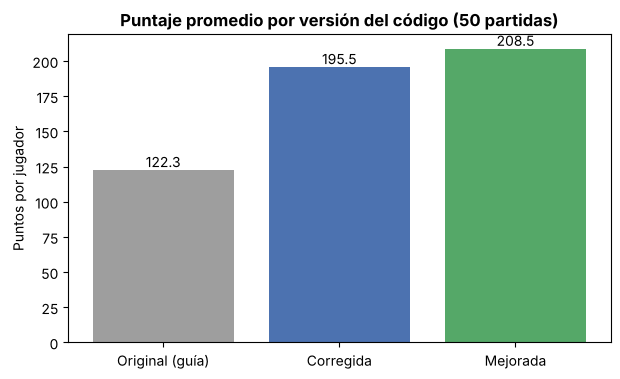

In [3]:
import time, statistics
import pandas as pd
import matplotlib.pyplot as plt

def choose_keep_mask_original(current_values, rolls_remaining, available_categories,
                              sims_per_mask, chooser=best_category_score):
    """Versión de la guía base, con el error 1 (rolls_remaining - 1), para comparar."""
    best_mask, best_ev = None, -1.0
    for mask in all_keep_masks():
        ev = simulate_expected_value_after_keeps(current_values, mask, rolls_remaining - 1,
                                                 available_categories, sims_per_mask, chooser)
        if ev > best_ev:
            best_ev, best_mask = ev, mask
    return best_mask

def jugar_n_partidas(n, sims, chooser, original=False, seed=2026):
    global choose_keep_mask_montecarlo
    corregida = choose_keep_mask_montecarlo
    if original:
        choose_keep_mask_montecarlo = choose_keep_mask_original
    random.seed(seed)
    puntajes = []
    try:
        for _ in range(n):
            s = play_game(sims, chooser)
            puntajes += [p.total for p in s.players]
    finally:
        choose_keep_mask_montecarlo = corregida
    return puntajes

N_PARTIDAS, SIMS = 50, 20
versiones = {
    "Original (guía)": jugar_n_partidas(N_PARTIDAS, SIMS, best_category_score, original=True),
    "Corregida": jugar_n_partidas(N_PARTIDAS, SIMS, best_category_score),
    "Mejorada": jugar_n_partidas(N_PARTIDAS, SIMS, smart_category_score),
}
df_est = pd.DataFrame([{"Versión": k, "Puntaje promedio": round(statistics.mean(v), 1),
                        "Desv. estándar": round(statistics.stdev(v), 1),
                        "Mínimo": min(v), "Máximo": max(v)} for k, v in versiones.items()])
print(df_est.to_string(index=False))

plt.figure(figsize=(7, 4))
bars = plt.bar(df_est["Versión"], df_est["Puntaje promedio"], color=["#9e9e9e", "#4c72b0", "#55a868"])
plt.bar_label(bars, fmt="%.1f")
plt.title("Puntaje promedio por versión del código (50 partidas)", fontweight="bold")
plt.ylabel("Puntos por jugador")
plt.show()

## 4. Efecto de `SIMS_PER_MASK` (corrección del error 2)

En la guía base el tiempo era casi igual con 10, 1.000 o 100.000 simulaciones, porque el parámetro no se aplicaba.
Ahora el número de simulaciones sí cambia el tiempo de cálculo. Con pocas partidas (10) el puntaje promedio todavía tiene variación aleatoria; por eso en la sección 5.4 se usan 500 partidas.

 Sims por máscara  Tiempo por partida (s)  Puntaje promedio
                5                    0.04             183.4
               20                    0.13             183.7
              100                    0.60             217.3
              300                    1.78             203.5


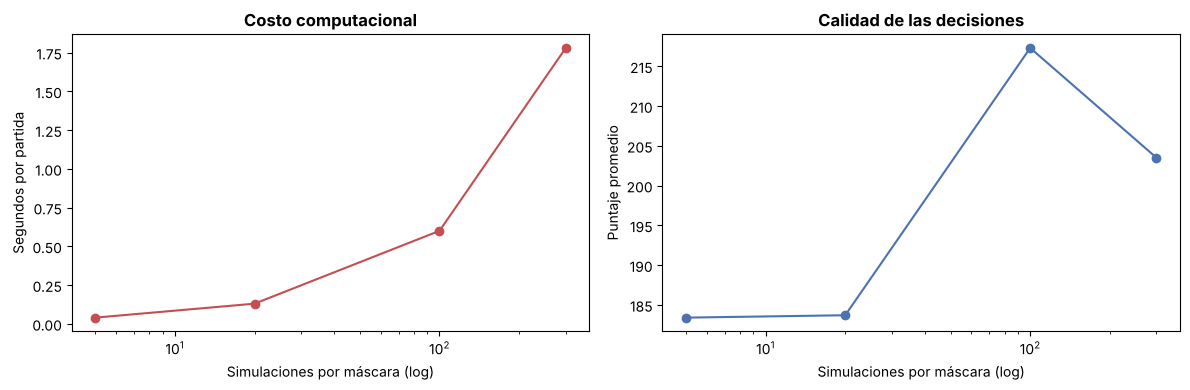

In [4]:
filas = []
for sims in [5, 20, 100, 300]:
    random.seed(11)
    t0 = time.time()
    pts = []
    for _ in range(10):
        s = play_game(sims, best_category_score)
        pts += [p.total for p in s.players]
    filas.append({"Sims por máscara": sims, "Tiempo por partida (s)": round((time.time() - t0) / 10, 2),
                  "Puntaje promedio": round(statistics.mean(pts), 1)})
df_sims = pd.DataFrame(filas)
print(df_sims.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(df_sims["Sims por máscara"], df_sims["Tiempo por partida (s)"], "o-", color="#c44e52")
ax[0].set_xscale("log"); ax[0].set_title("Costo computacional", fontweight="bold")
ax[0].set_xlabel("Simulaciones por máscara (log)"); ax[0].set_ylabel("Segundos por partida")
ax[1].plot(df_sims["Sims por máscara"], df_sims["Puntaje promedio"], "o-", color="#4c72b0")
ax[1].set_xscale("log"); ax[1].set_title("Calidad de las decisiones", fontweight="bold")
ax[1].set_xlabel("Simulaciones por máscara (log)"); ax[1].set_ylabel("Puntaje promedio")
plt.tight_layout(); plt.show()

## 5. Ley de los Grandes Números

La Ley de los Grandes Números dice que, al aumentar el número de repeticiones de un experimento aleatorio,
el promedio observado se acerca al valor esperado teórico. Se comprueba en cuatro experimentos.

### 5.1 Frecuencia de cada cara del dado (valor teórico: 1/6 = 16,67 %)

 Lanzamientos  Cara 1  Cara 2  Cara 3  Cara 4  Cara 5  Cara 6  Error máx. (%)
           10   20.00   10.00   10.00   40.00   10.00   10.00          23.333
          100   17.00   13.00   12.00   23.00   15.00   20.00           6.333
         1000   16.00   16.60   16.50   16.30   18.30   16.30           1.633
        10000   16.24   16.99   16.49   16.86   17.15   16.27           0.483
       100000   16.63   16.73   16.52   16.85   16.72   16.55           0.184
      1000000   16.68   16.69   16.61   16.67   16.72   16.62           0.056


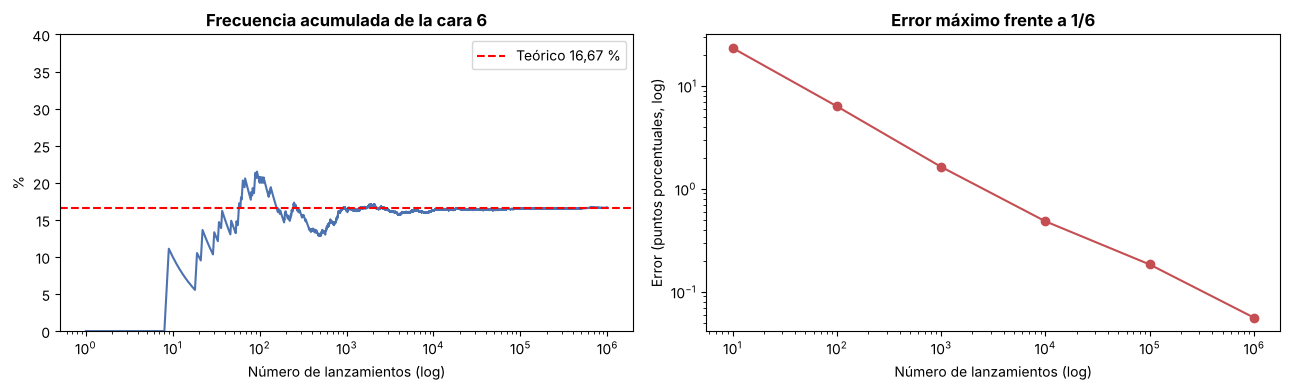

In [5]:
import numpy as np
random.seed(1)
N_MAX = 1_000_000
lanzamientos = [roll_single_die() for _ in range(N_MAX)]
puntos = [10, 100, 1_000, 10_000, 100_000, 1_000_000]

filas = []
for n in puntos:
    c = Counter(lanzamientos[:n])
    frec = [c.get(k, 0) / n * 100 for k in range(1, 7)]
    filas.append({"Lanzamientos": n, **{f"Cara {k}": round(f, 2) for k, f in zip(range(1, 7), frec)},
                  "Error máx. (%)": round(max(abs(f - 100 / 6) for f in frec), 3)})
df_caras = pd.DataFrame(filas)
print(df_caras.to_string(index=False))

seis = np.cumsum(np.array(lanzamientos) == 6) / np.arange(1, N_MAX + 1) * 100
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(np.arange(1, N_MAX + 1), seis, color="#4c72b0")
ax[0].axhline(100 / 6, color="red", ls="--", label="Teórico 16,67 %")
ax[0].set_xscale("log"); ax[0].set_ylim(0, 40)
ax[0].set_title("Frecuencia acumulada de la cara 6", fontweight="bold")
ax[0].set_xlabel("Número de lanzamientos (log)"); ax[0].set_ylabel("%"); ax[0].legend()
ax[1].plot(df_caras["Lanzamientos"], df_caras["Error máx. (%)"], "o-", color="#c44e52")
ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_title("Error máximo frente a 1/6", fontweight="bold")
ax[1].set_xlabel("Número de lanzamientos (log)"); ax[1].set_ylabel("Error (puntos porcentuales, log)")
plt.tight_layout(); plt.show()

### 5.2 Probabilidad de sacar Yahtzee en un turno

Estrategia: guardar siempre el valor más repetido y relanzar el resto (3 lanzamientos).
El valor teórico se calcula **de forma exacta** con una cadena de Markov (≈ 4,60 %) y se compara con la simulación.

Probabilidad teórica exacta: 347897/7558272 ≈ 4.603 %


 Turnos simulados  P(Yahtzee) simulada (%)  Error (pp)
              100                    4.000       0.603
             1000                    5.100       0.497
            10000                    4.710       0.107
           100000                    4.560       0.043
           200000                    4.611       0.008


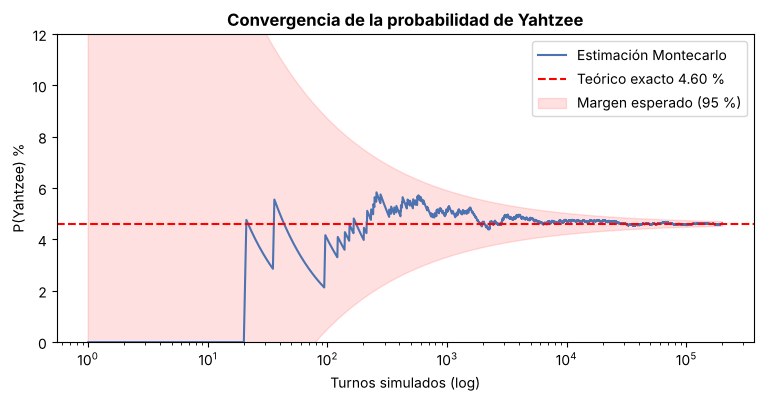

In [6]:
from fractions import Fraction
from itertools import product

def prob_yahtzee_exacta() -> Fraction:
    """Probabilidad exacta de Yahtzee en 3 lanzamientos guardando el valor más repetido."""
    # Estado = cuántos dados iguales se tienen (0 = aún no se ha lanzado)
    dist = {0: Fraction(1)}
    for _ in range(3):
        nueva = Counter()
        for k, p in dist.items():
            n = 5 - k
            if n == 0:
                nueva[5] += p
                continue
            for res in product(range(1, 7), repeat=n):
                c = Counter(res)
                if k == 0:
                    nk = max(c.values())
                else:
                    # el valor guardado es 1 (por simetría); se suma lo que coincida
                    nk = max(k + c.get(1, 0), max(c.values()))
                nueva[nk] += p * Fraction(1, 6 ** n)
        dist = nueva
    return dist[5]

P_TEORICA = prob_yahtzee_exacta()
print(f"Probabilidad teórica exacta: {P_TEORICA} ≈ {float(P_TEORICA)*100:.3f} %")

def turno_busca_yahtzee() -> bool:
    dados = [roll_single_die() for _ in range(5)]
    for _ in range(2):
        valor, cuantos = Counter(dados).most_common(1)[0]
        if cuantos == 5:
            return True
        dados = [valor] * cuantos + [roll_single_die() for _ in range(5 - cuantos)]
    return len(set(dados)) == 1

random.seed(3)
N_TURNOS = 200_000
exitos = np.array([turno_busca_yahtzee() for _ in range(N_TURNOS)])
estim = np.cumsum(exitos) / np.arange(1, N_TURNOS + 1) * 100

filas = [{"Turnos simulados": n, "P(Yahtzee) simulada (%)": round(estim[n - 1], 3),
          "Error (pp)": round(abs(estim[n - 1] - float(P_TEORICA) * 100), 3)}
         for n in [100, 1_000, 10_000, 100_000, 200_000]]
print(pd.DataFrame(filas).to_string(index=False))

n = np.arange(1, N_TURNOS + 1); p = float(P_TEORICA)
banda = 1.96 * np.sqrt(p * (1 - p) / n) * 100
plt.figure(figsize=(9, 4))
plt.plot(n, estim, color="#4c72b0", label="Estimación Montecarlo")
plt.axhline(p * 100, color="red", ls="--", label=f"Teórico exacto {p*100:.2f} %")
plt.fill_between(n, p * 100 - banda, p * 100 + banda, color="red", alpha=0.12, label="Margen esperado (95 %)")
plt.xscale("log"); plt.ylim(0, 12)
plt.title("Convergencia de la probabilidad de Yahtzee", fontweight="bold")
plt.xlabel("Turnos simulados (log)"); plt.ylabel("P(Yahtzee) %"); plt.legend()
plt.show()

### 5.3 Convergencia del valor esperado de una decisión (corrección del error 4)

Dados `[3, 3, 5, 2, 6]`, se conservan los dos 3. En la guía base, la "línea teórica" era el último valor simulado.
Aquí el valor esperado se calcula **exactamente** recorriendo los 6³ = 216 resultados posibles.

Valor esperado exacto: 17.3009



 Iteraciones  EV estimado  Error absoluto
          10      16.9000          0.4009
         100      17.0800          0.2209
        1000      17.0780          0.2229
       10000      17.3231          0.0222
      100000      17.3169          0.0160


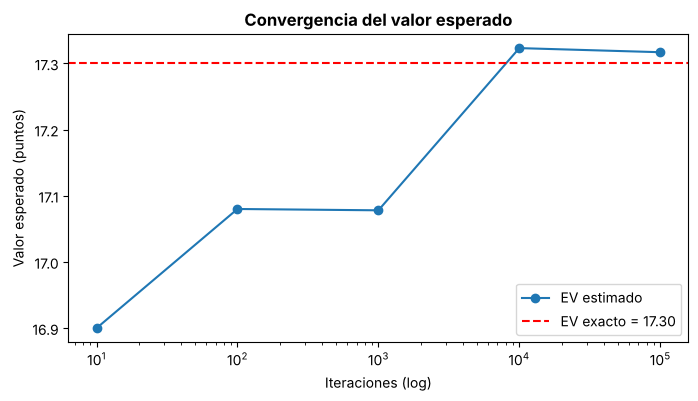

In [7]:
dados_iniciales = [3, 3, 5, 2, 6]
categorias = ["threes", "fullHouse", "threeOfKind", "chance"]
mascara = [True, True, False, False, False]

ev_exacto = sum(best_category_score([3, 3] + list(r), categorias)[1]
                for r in product(range(1, 7), repeat=3)) / 216
print(f"Valor esperado exacto: {ev_exacto:.4f}\n")

random.seed(5)
filas = []
for sims in [10, 100, 1_000, 10_000, 100_000]:
    ev = simulate_expected_value_after_keeps(dados_iniciales, mascara, 1, categorias, sims)
    filas.append({"Iteraciones": sims, "EV estimado": round(ev, 4), "Error absoluto": round(abs(ev - ev_exacto), 4)})
df_ev = pd.DataFrame(filas)
print(df_ev.to_string(index=False))

plt.figure(figsize=(8, 4))
plt.plot(df_ev["Iteraciones"], df_ev["EV estimado"], "o-", label="EV estimado")
plt.axhline(ev_exacto, color="red", ls="--", label=f"EV exacto = {ev_exacto:.2f}")
plt.xscale("log"); plt.legend()
plt.title("Convergencia del valor esperado", fontweight="bold")
plt.xlabel("Iteraciones (log)"); plt.ylabel("Valor esperado (puntos)")
plt.show()

### 5.4 Estabilidad del puntaje promedio de una partida completa

Se juegan 500 partidas completas (1.000 puntajes de jugador) con la estrategia mejorada.
El promedio acumulado se estabiliza y el intervalo de confianza del 95 % se estrecha a medida que crece el número de partidas.

Tiempo: 69.3 s
 Puntajes  Promedio  IC 95 % (±)
       10    222.40        20.21
       50    210.98         8.30
      100    208.71         6.09
      500    210.16         3.34
     1000    210.89         2.45


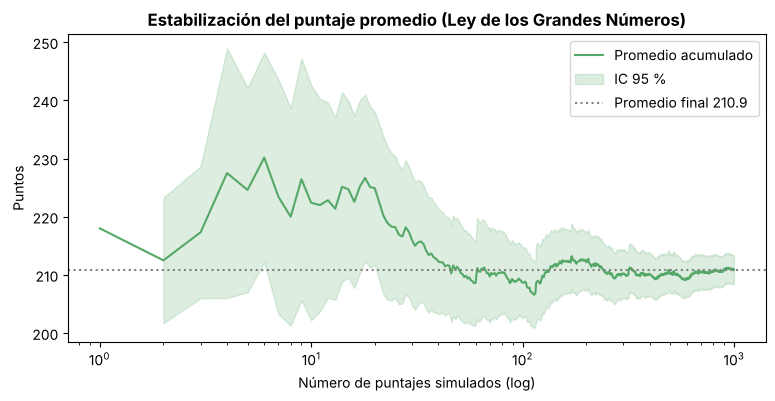

In [8]:
random.seed(2027)
t0 = time.time()
puntajes = []
for _ in range(500):
    s = play_game(20, smart_category_score)
    puntajes += [p.total for p in s.players]
print(f"Tiempo: {time.time() - t0:.1f} s")

x = np.array(puntajes, dtype=float)
n = np.arange(1, len(x) + 1)
media = np.cumsum(x) / n
desv = np.array([x[:k].std(ddof=1) if k > 1 else 0 for k in n])
ic = 1.96 * desv / np.sqrt(n)

filas = [{"Puntajes": k, "Promedio": round(media[k - 1], 2), "IC 95 % (±)": round(ic[k - 1], 2)}
         for k in [10, 50, 100, 500, 1000]]
print(pd.DataFrame(filas).to_string(index=False))

plt.figure(figsize=(9, 4))
plt.plot(n, media, color="#55a868", label="Promedio acumulado")
plt.fill_between(n[1:], (media - ic)[1:], (media + ic)[1:], color="#55a868", alpha=0.2, label="IC 95 %")
plt.axhline(media[-1], color="gray", ls=":", label=f"Promedio final {media[-1]:.1f}")
plt.xscale("log")
plt.title("Estabilización del puntaje promedio (Ley de los Grandes Números)", fontweight="bold")
plt.xlabel("Número de puntajes simulados (log)"); plt.ylabel("Puntos")
plt.legend(); plt.show()

## 6. Diagrama de flujo del turno (corrección del error 3)

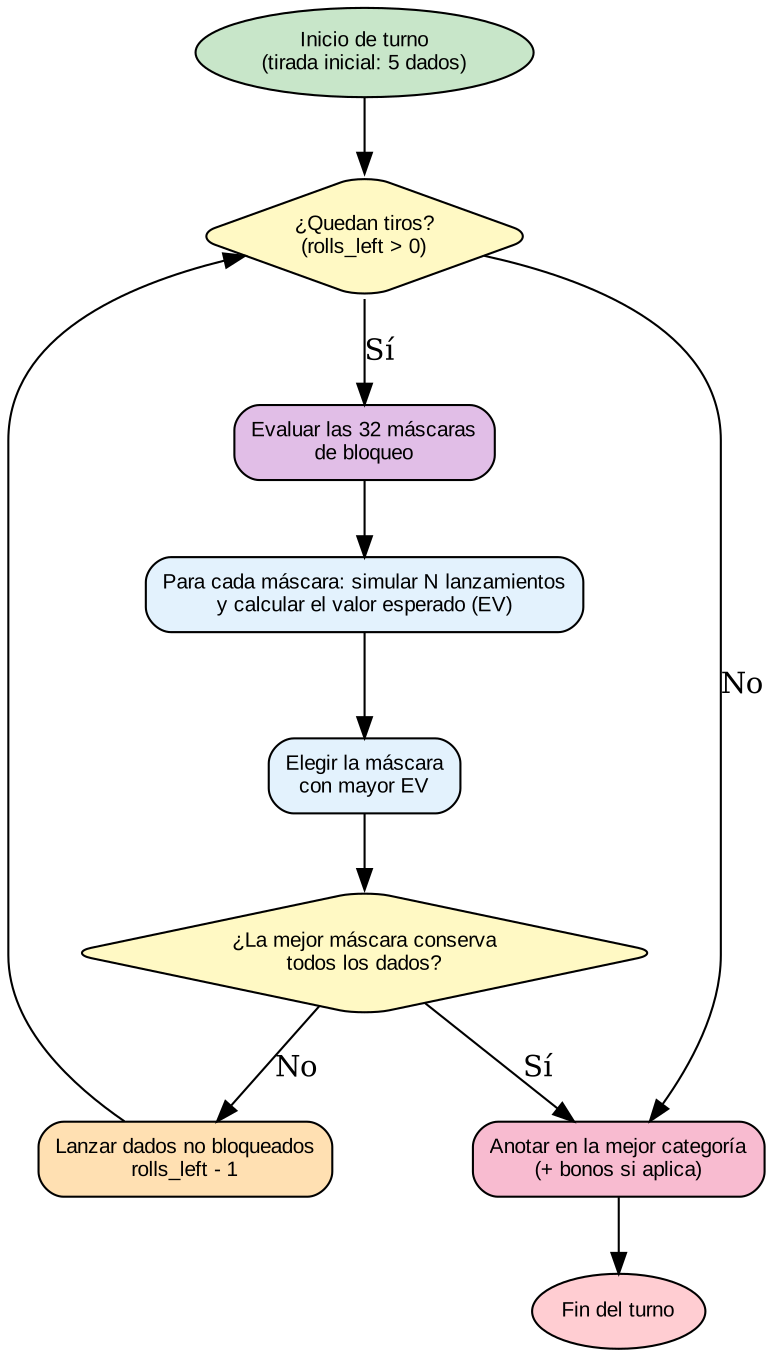

In [9]:
from graphviz import Digraph
from IPython.display import Image, display

def generar_diagrama_flujo():
    dot = Digraph(comment="Algoritmo Yahtzee Montecarlo", format="png")
    dot.attr(rankdir="TB", dpi="150")
    dot.attr("node", shape="box", style="filled,rounded", fontname="Arial", fontsize="10", fillcolor="#E3F2FD")
    dot.node("inicio", "Inicio de turno\n(tirada inicial: 5 dados)", fillcolor="#C8E6C9", shape="ellipse")
    dot.node("eval_tiros", "¿Quedan tiros?\n(rolls_left > 0)", shape="diamond", fillcolor="#FFF9C4")
    dot.node("eval_mascaras", "Evaluar las 32 máscaras\nde bloqueo", fillcolor="#E1BEE7")
    dot.node("montecarlo", "Para cada máscara: simular N lanzamientos\ny calcular el valor esperado (EV)")
    dot.node("mejor_mascara", "Elegir la máscara\ncon mayor EV")
    dot.node("plantarse", "¿La mejor máscara conserva\ntodos los dados?", shape="diamond", fillcolor="#FFF9C4")
    dot.node("actualizar", "Lanzar dados no bloqueados\nrolls_left - 1", fillcolor="#FFE0B2")
    dot.node("anotar", "Anotar en la mejor categoría\n(+ bonos si aplica)", fillcolor="#F8BBD0")
    dot.node("fin", "Fin del turno", fillcolor="#FFCDD2", shape="ellipse")
    dot.edge("inicio", "eval_tiros")
    dot.edge("eval_tiros", "eval_mascaras", label="Sí")
    dot.edge("eval_tiros", "anotar", label="No")
    dot.edge("eval_mascaras", "montecarlo")
    dot.edge("montecarlo", "mejor_mascara")
    # MODIFICA (error 3): se eliminó dot.edge('mejor_mask_decision', 'plantarse'), un nodo inexistente
    dot.edge("mejor_mascara", "plantarse")
    dot.edge("plantarse", "anotar", label="Sí")
    dot.edge("plantarse", "actualizar", label="No")
    dot.edge("actualizar", "eval_tiros")
    dot.edge("anotar", "fin")
    return dot

ruta = generar_diagrama_flujo().render("diagrama_flujo_yahtzee", cleanup=True)
display(Image(ruta))